# 01 - Structure QC (Phases 1 and 2)

Read the AlphaFold confidence, then check the prediction against an experimental
structure. Nothing downstream should run until the pass checks at the bottom are met.

**Pass check 1** - pLDDT profile exists, active-site residues (including Asp27) sit at 70
or above, and the Met20 loop is identified on the profile.

**Pass check 2** - backbone RMSD recorded, per-residue deviation figure exists, and the
worst-fitting region is named.

Kernel: **Python (dhfr)**.

In [1]:
import sys

sys.path.insert(0, "../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dhfr_lib as D

PY = sys.executable
D.toolchain()

Matplotlib is building the font cache; this may take a moment.


{'rdkit': '2026.09.2',
 'biopython': '1.88',
 'meeko': '0.8.0',
 'vina': 'AutoDock Vina v1.2.7'}

## Identifiers

`P00374` is human DHFR. The project-plan PDF says `P00382`; that is an *E. coli*
trimethoprim-resistance enzyme. See `notes/identifiers.md`.

In [2]:
ECOLI = "P0ABQ4"   # E. coli DHFR, folA, 159 aa - main target
HUMAN = "P00374"   # Homo sapiens DHFR, 187 aa - selectivity comparison

# Regions of interest in E. coli DHFR numbering (matches 1RX2 chain A directly).
MET20_LOOP = (9, 24)
FG_LOOP = (116, 132)
GH_LOOP = (142, 150)
ADENOSINE_SUBDOMAIN = (38, 88)
ASP27 = 27

af = {acc: D.fetch_alphafold(acc) for acc in (ECOLI, HUMAN)}
xtal = D.fetch_pdb("1RX2")

pd.DataFrame(
    [{"accession": a, "file": p.name, "kb": round(p.stat().st_size / 1024)}
     for a, d in af.items() for p in d.values()]
)

,accession,file,kb
0,P0ABQ4,AF-P0ABQ4-F1-model_v6.pdb,105
1,P0ABQ4,AF-P0ABQ4-F1-model_v6.cif,156
2,P0ABQ4,AF-P0ABQ4-F1-confidence_v6.json,2
3,P0ABQ4,AF-P0ABQ4-F1-predicted_aligned_error_v6.json,50
4,P00374,AF-P00374-F1-model_v6.pdb,125
5,P00374,AF-P00374-F1-model_v6.cif,183
6,P00374,AF-P00374-F1-confidence_v6.json,2
7,P00374,AF-P00374-F1-predicted_aligned_error_v6.json,70


## pLDDT profile

AlphaFold stores pLDDT in the B-factor column, so BioPython can read it straight out
of the model file.

In [3]:
import warnings

from Bio.PDB import PDBParser
from Bio.PDB.PDBExceptions import PDBConstructionWarning

warnings.simplefilter("ignore", PDBConstructionWarning)
parser = PDBParser(QUIET=True)


def plddt_profile(pdb_path):
    chain = next(iter(parser.get_structure("af", pdb_path)[0]))
    out = {}
    for res in chain:
        if res.id[0] != " ":
            continue
        atoms = list(res)
        out[res.id[1]] = sum(a.bfactor for a in atoms) / len(atoms)
    return pd.Series(out, name="plddt")


plddt = {acc: plddt_profile(af[acc]["pdb"]) for acc in (ECOLI, HUMAN)}

for acc, s in plddt.items():
    print(f"{acc}: {len(s)} residues, mean pLDDT {s.mean():.1f}, min {s.min():.1f}")

P0ABQ4: 159 residues, mean pLDDT 96.5, min 75.8
P00374: 187 residues, mean pLDDT 96.1, min 41.6


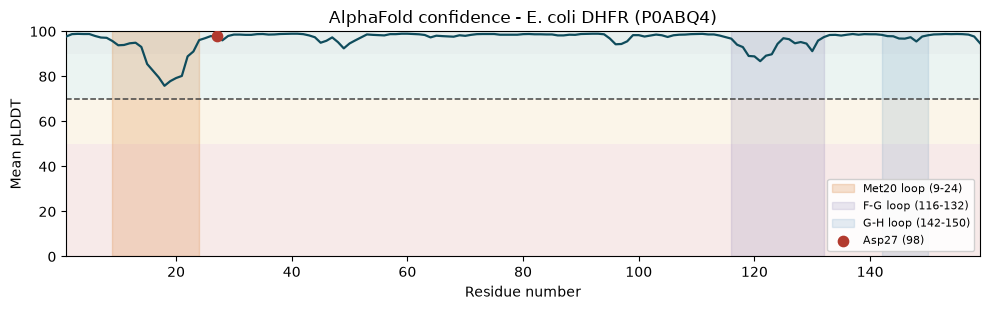

In [4]:
BANDS = [(90, 100, "#1b6b5a", "very high"), (70, 90, "#3f9c86", "confident"),
         (50, 70, "#d9a62b", "low"), (0, 50, "#b23a2e", "very low")]

s = plddt[ECOLI]
fig, ax = plt.subplots(figsize=(10, 3.2))

for lo, hi, colour, _ in BANDS:
    ax.axhspan(lo, hi, color=colour, alpha=0.10, lw=0)

ax.axvspan(*MET20_LOOP, color="#d97a2b", alpha=0.22, label="Met20 loop (9-24)")
ax.axvspan(*FG_LOOP, color="#7a6ea8", alpha=0.16, label="F-G loop (116-132)")
ax.axvspan(*GH_LOOP, color="#5a8fb8", alpha=0.16, label="G-H loop (142-150)")

ax.plot(s.index, s.values, lw=1.6, color="#0f4c5c", zorder=3)
ax.axhline(70, ls="--", lw=1.1, color="#444", zorder=2)
ax.scatter([ASP27], [s.loc[ASP27]], s=55, color="#b23a2e", zorder=5,
           label=f"Asp27 ({s.loc[ASP27]:.0f})")

ax.set_xlabel("Residue number")
ax.set_ylabel("Mean pLDDT")
ax.set_title(f"AlphaFold confidence - E. coli DHFR ({ECOLI})")
ax.set_ylim(0, 100)
ax.set_xlim(1, len(s))
ax.legend(loc="lower right", fontsize=8, framealpha=0.9)
fig.tight_layout()
fig.savefig(D.FIGURES / "fig1_plddt_profile.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
# Active-site residues must sit in the 70+ bands before docking.
ACTIVE_SITE = [5, 6, 7, 20, 27, 28, 30, 31, 50, 52, 54, 57, 94, 100, 113]

site = s.loc[[r for r in ACTIVE_SITE if r in s.index]]
below = site[site < 70]

print(f"active-site residues checked : {len(site)}")
print(f"minimum pLDDT in the site    : {site.min():.1f} (residue {site.idxmin()})")
print(f"Asp27 pLDDT                  : {s.loc[ASP27]:.1f}")
print(f"Met20 loop mean pLDDT        : {s.loc[MET20_LOOP[0]:MET20_LOOP[1]].mean():.1f}")
print()
print("PASS check 1a" if below.empty else f"FAIL - below 70: {below.to_dict()}")

active-site residues checked : 15
minimum pLDDT in the site    : 79.2 (residue 20)
Asp27 pLDDT                  : 97.8
Met20 loop mean pLDDT        : 87.7

PASS check 1a


## PAE

Low PAE between two regions means their *relative* position is confidently predicted.
High PAE across the Met20 loop marks its placement as uncertain even when its local
shape scores well.

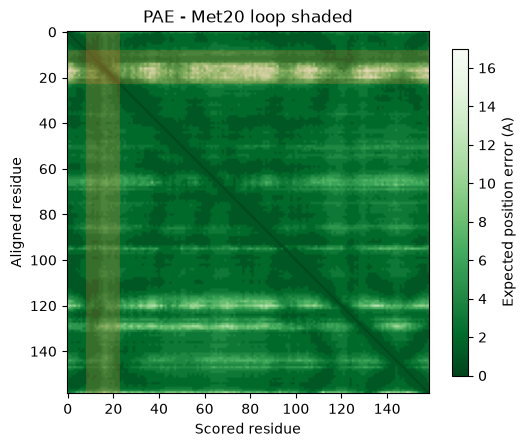

mean PAE overall          : 2.83 A
mean PAE for Met20 loop   : 5.40 A


In [6]:
import json

pae_raw = json.loads(af[ECOLI]["pae"].read_text())
entry = pae_raw[0] if isinstance(pae_raw, list) else pae_raw
pae = np.array(entry["predicted_aligned_error"], dtype=float)

fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(pae, cmap="Greens_r", origin="upper", vmin=0, vmax=pae.max())
for lo, hi in (MET20_LOOP,):
    ax.axhspan(lo - 1, hi - 1, color="#d97a2b", alpha=0.25, lw=0)
    ax.axvspan(lo - 1, hi - 1, color="#d97a2b", alpha=0.25, lw=0)
ax.set_xlabel("Scored residue")
ax.set_ylabel("Aligned residue")
ax.set_title("PAE - Met20 loop shaded")
fig.colorbar(im, ax=ax, label="Expected position error (A)", shrink=0.85)
fig.tight_layout()
fig.savefig(D.FIGURES / "fig1b_pae.png", dpi=300, bbox_inches="tight")
plt.show()

lo, hi = MET20_LOOP
met20_block = pae[lo - 1:hi, :]
print(f"mean PAE overall          : {pae.mean():.2f} A")
print(f"mean PAE for Met20 loop   : {met20_block.mean():.2f} A")

## Superposition against 1RX2

`1RX2` chain A is numbered 1-159 and matches UniProt numbering directly, so CA atoms
pair on residue number with no offset. Expect exactly one sequence mismatch at
position 37 (Asn in UniProt, Asp in the crystal).

In [7]:
from Bio.PDB import Superimposer


def ca_atoms(pdb_path, chain_id=None):
    model = parser.get_structure("s", pdb_path)[0]
    chain = model[chain_id] if chain_id else next(iter(model))
    return {r.id[1]: r["CA"] for r in chain if r.id[0] == " " and "CA" in r}


pred = ca_atoms(af[ECOLI]["pdb"])
crys = ca_atoms(xtal, "A")
common = sorted(set(pred) & set(crys))
print(f"paired CA atoms: {len(common)} (pred {len(pred)}, crystal {len(crys)})")

sup = Superimposer()
sup.set_atoms([crys[i] for i in common], [pred[i] for i in common])
print(f"backbone RMSD (all CA): {sup.rms:.3f} A")

# Apply the transform to a copy so per-residue deviations are measured post-fit.
pred_struct = parser.get_structure("pred", af[ECOLI]["pdb"])
sup.apply(list(pred_struct.get_atoms()))
pred_fitted = {r.id[1]: r["CA"] for r in next(iter(pred_struct[0])) if r.id[0] == " "}

dev = pd.Series(
    {i: float(np.linalg.norm(pred_fitted[i].coord - crys[i].coord)) for i in common},
    name="deviation",
)
print(f"max per-residue deviation: {dev.max():.2f} A at residue {dev.idxmax()}")

paired CA atoms: 159 (pred 159, crystal 159)
backbone RMSD (all CA): 0.361 A
max per-residue deviation: 1.09 A at residue 148


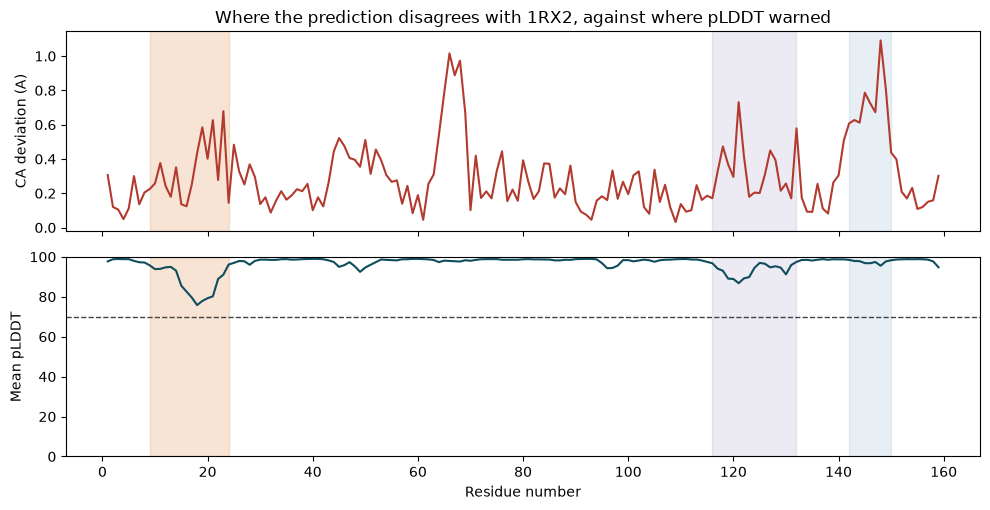

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)

for ax in (ax1, ax2):
    ax.axvspan(*MET20_LOOP, color="#d97a2b", alpha=0.20)
    ax.axvspan(*FG_LOOP, color="#7a6ea8", alpha=0.14)
    ax.axvspan(*GH_LOOP, color="#5a8fb8", alpha=0.14)

ax1.plot(dev.index, dev.values, lw=1.5, color="#b23a2e")
ax1.set_ylabel("CA deviation (A)")
ax1.set_title("Where the prediction disagrees with 1RX2, against where pLDDT warned")

ax2.plot(s.index, s.values, lw=1.5, color="#0f4c5c")
ax2.axhline(70, ls="--", lw=1.0, color="#444")
ax2.set_ylabel("Mean pLDDT")
ax2.set_xlabel("Residue number")
ax2.set_ylim(0, 100)

fig.tight_layout()
fig.savefig(D.FIGURES / "fig2_deviation_vs_plddt.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
def region_stats(name, lo, hi):
    d = dev.loc[lo:hi]
    p = s.loc[lo:hi]
    return {"region": name, "residues": f"{lo}-{hi}",
            "mean_dev": round(d.mean(), 2), "max_dev": round(d.max(), 2),
            "mean_plddt": round(p.mean(), 1)}


regions = pd.DataFrame([
    region_stats("Met20 loop", *MET20_LOOP),
    region_stats("F-G loop", *FG_LOOP),
    region_stats("G-H loop", *GH_LOOP),
    region_stats("adenosine subdomain", *ADENOSINE_SUBDOMAIN),
    region_stats("whole chain", int(dev.index.min()), int(dev.index.max())),
]).sort_values("mean_dev", ascending=False)
regions

,region,residues,mean_dev,max_dev,mean_plddt
2,G-H loop,142-150,0.71,1.09,97.4
1,F-G loop,116-132,0.34,0.73,93.2
3,adenosine subdomain,38-88,0.34,1.02,98.0
0,Met20 loop,9-24,0.33,0.68,87.7
4,whole chain,1-159,0.30,1.09,96.5


## Pass checks

In [10]:
worst = regions.iloc[0]
rmsd = float(sup.rms)

if rmsd < 1.0:
    reading = "essentially the same backbone"
elif rmsd < 2.0:
    reading = "same fold, meaningful local differences - normal for prediction vs holo crystal"
else:
    reading = "OVER 2 A - diagnose before proceeding"

summary = pd.DataFrame([{
    "comparison": f"AlphaFold {ECOLI} vs 1RX2 chain A",
    "paired_CA": len(common),
    "backbone_rmsd_A": round(rmsd, 3),
    "reading": reading,
    "worst_region": worst["region"],
    "worst_region_mean_dev_A": worst["mean_dev"],
    "worst_region_mean_plddt": worst["mean_plddt"],
    "plddt_predicted_it": bool(worst["mean_plddt"] < s.mean()),
    "asp27_plddt": round(float(s.loc[ASP27]), 1),
    "active_site_min_plddt": round(float(site.min()), 1),
}])
summary.to_csv(D.RESULTS / "comparison.csv", index=False)

print(f"PASS 1 - active site >= 70      : {below.empty}")
print(f"PASS 1 - pLDDT figure written   : {(D.FIGURES / 'fig1_plddt_profile.png').exists()}")
print(f"PASS 2 - RMSD recorded          : {rmsd:.3f} A ({reading})")
print(f"PASS 2 - deviation figure       : {(D.FIGURES / 'fig2_deviation_vs_plddt.png').exists()}")
print(f"PASS 2 - worst region           : {worst['region']} "
      f"(mean {worst['mean_dev']} A, pLDDT {worst['mean_plddt']})")
print()
print("wrote", D.RESULTS / "comparison.csv")
summary.T

PASS 1 - active site >= 70      : True
PASS 1 - pLDDT figure written   : True
PASS 2 - RMSD recorded          : 0.361 A (essentially the same backbone)
PASS 2 - deviation figure       : True
PASS 2 - worst region           : G-H loop (mean 0.71 A, pLDDT 97.4)

wrote /Users/leon-ticharwa/Documents/repos/Leon-Ticharwa-Biomed/dhfr-trimethoprim/results/comparison.csv


,0
comparison,AlphaFold P0ABQ4 vs 1RX2 chain A
paired_CA,159
backbone_rmsd_A,0.361
reading,essentially the same backbone
worst_region,G-H loop
worst_region_mean_dev_A,0.71
worst_region_mean_plddt,97.4
plddt_predicted_it,False
asp27_plddt,97.8
active_site_min_plddt,79.2
